# Robust RFF regression with sample splitting + ITGD

Pipeline:

1. **Clean data.** $X\sim\mathcal N(0,I_d)$ (sub-Gaussian), $Y=f_\star(X)+\xi$ with $\xi\sim\mathcal N(0,s^2)$
   (conditionally sub-Gaussian noise, §Statistical model). The target satisfies the **kernel source condition**
   (eq. kernel-source) $f_\star=T^rg$, $\|g\|_{L^2(P_X)}\le R$, where $T$ is the integral operator of the Gaussian
   kernel $k_\sigma$ under $P_X$ — so the Gaussian kernel is the "correct" kernel for this data.
2. **Contamination.** Strong replacement of complete pairs $(x,y)$ in **input space**,    before
   the random feature map is applied: corrupted points enter the pipeline as $\Phi(x^{\rm corr})$. The adversary acts on
   the full sample *before* the split.
3. **Sample splitting.** A random half $A$ is used only to robustly estimate the feature second moment
   $M=\mathbb E[ZZ^\top]$, $Z=\Phi(X)$; the other half $B$ is used only for regression on random Fourier features.
4. **ITGD.** `itgd_linear` (from `algorithms/itgd_scaled.py`) runs on half $B$, whitening with the robust $\widehat M$ from half $A$.
5. **Comparison.** The resulting hypothesis $\widehat f(x)=\widehat\beta^\top\Phi(x)$ is compared with the exact clean
   KRR solution $\widehat f_\lambda$ (fit on the uncorrupted sample) for a range of $\epsilon$, in $L^2(P_X)$.

Normalization throughout: $\frac1n\sum(y_i-f(x_i))^2+\lambda\|f\|^2$, i.e. $\bm\alpha=(K+n\lambda I)^{-1}\bm y$
(sklearn `KernelRidge(alpha=n·λ)`), and RFF ridge $(\widehat M+\lambda I)^{-1}\widehat c$.

In [29]:
import sys, os
from itertools import combinations_with_replacement
from math import comb
sys.path.insert(0, os.path.abspath(".."))  # make repo root importable
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.kernel_ridge import KernelRidge
from algorithms.itgd_scaled import itgd_linear

SEED = 0
rng = np.random.default_rng(SEED)

# Fixed hypothesis -> (color, marker, linestyle). Colors follow random_features_test.ipynb;
# marker + linestyle give every series a second, non-color encoding.
STYLE = {
    "clean KRR":          ("#4a3aa7", "s", "-"),
    "corrupted KRR":      ("#7f4f24", "X", "-."),
    "oracle clean RFF":   ("#2a78d6", "o", "--"),
    "nonrobust RFF":      ("#eb6834", "v", "-"),
    "ITGD (robust M)":    ("#008300", "D", "-"),
    "ITGD (empirical M)": ("#eda100", "^", ":"),
    "ITGD (oracle M)":    ("#e87ba4", "P", "--"),
}
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
})

## 1. Clean data with a kernel source condition

For $P_X=\mathcal N(0,I_d)$ and the Gaussian kernel $k_\sigma(x,x')=e^{-\|x-x'\|^2/(2\sigma^2)}$, the integral operator
$(Tf)(x)=\mathbb E_{X'\sim P_X}[k_\sigma(x,X')f(X')]$ (eq. T) has a closed-form eigensystem (Zhu et al. 1998;
Rasmussen & Williams 2006, §4.3.1). In one coordinate, with $a=\tfrac14$, $b=\tfrac1{2\sigma^2}$, $c=\sqrt{a^2+2ab}$,
$A=a+b+c$ and $B=b/A$,

$$\lambda_k=\sqrt{2a/A}\;B^k,\qquad
\phi_k(x)=\sqrt{2\sqrt c}\;e^{-(c-a)x^2}\,\frac{H_k(\sqrt{2c}\,x)}{\sqrt{2^kk!}},\qquad k=0,1,\dots$$

where $H_k$ are the (physicists') Hermite polynomials and $\{\phi_k\}$ is orthonormal in $L^2(\mathcal N(0,1))$. Kernel and
$P_X$ both factor over coordinates, so the eigenfunctions of $T$ on $\mathbb R^d$ are the products
$\phi_\alpha(x)=\prod_j\phi_{\alpha_j}(x_j)$, $\alpha\in\mathbb N^d$, with eigenvalue $\mu_\alpha=\lambda_0^d\,B^{|\alpha|}$. The
eigenvalue depends only on the total degree $|\alpha|$, and $B$ is the factor by which the spectrum drops per degree.

The target is built exactly in this basis:

$$f_\star=T^rg=\sum_\alpha\mu_\alpha^r\,g_\alpha\,\phi_\alpha,\qquad
\|g\|^2_{L^2(P_X)}=\sum_\alpha g_\alpha^2,\qquad \|f_\star\|^2_{L^2(P_X)}=\sum_\alpha\mu_\alpha^{2r}g_\alpha^2 .$$

* **Truncation.** Eigenfunctions up to total degree $K$ are kept, $\binom{K+d}{d}$ of them, with $K$ the largest degree
  for which that count is at most `MAX_MODES`. The printed Mercer error $\max|k_\sigma(x,x')-\sum_\alpha\mu_\alpha\phi_\alpha(x)\phi_\alpha(x')|$
  and the energy in degree $K$ show whether the truncation matters.
* **$g$.** White noise over the kept eigenfunctions (the analogue of white noise on reference points), except that the
  constant mode $\alpha=0$ is set to zero: $\mu_0$ is by far the largest eigenvalue, so it would make $f_\star$ mostly a
  constant offset that says nothing about the kernel.
* **Scale.** $f_\star$ is rescaled to $\|f_\star\|_{L^2(P_X)}=1$ exactly, from its coefficients; $R=\|g\|_{L^2(P_X)}$ is
  reported after the rescaling.
* **Smoothness.** $r\ge1/2$ places $f_\star$ in the RKHS. The expected energy of $f_\star$ in degree $k$ is proportional to
  $\binom{k+d-1}{d-1}B^{2rk}$, so $r$ and $\sigma$ (through $B$) set how nonlinear $f_\star$ is: smaller $r$ or larger $B$
  moves energy to higher degrees.


In [30]:
d, noise = 10, 0.3                # input dim, noise std
sigma = 2.0 * np.sqrt(d / 5)      # kernel width ~ sqrt(d): typical ||x - x'||^2 = 2d, so k(x, x') ~ e^{-5/4} for every d
r_source = 1.0                    # source exponent r in f* = T^r g
MAX_MODES = 5000                  # cap on the number of eigenfunctions kept (sets the degree truncation K)


def gaussian_kernel(X1, X2, sigma):
    sq = np.sum(X1**2, 1)[:, None] - 2 * X1 @ X2.T + np.sum(X2**2, 1)[None, :]
    return np.exp(-np.maximum(sq, 0) / (2 * sigma**2))


def sample_x(n, rng):
    return rng.normal(size=(n, d))


# --- closed-form eigensystem of T in one coordinate (Rasmussen & Williams 2006, Sec. 4.3.1) ---
a_h, b_h = 1 / 4, 1 / (2 * sigma**2)      # a^{-1} = 4 Var(X_j), b^{-1} = 2 sigma^2
c_h = np.sqrt(a_h**2 + 2 * a_h * b_h)
B_h = b_h / (a_h + b_h + c_h)             # eigenvalue ratio per unit of polynomial degree
lam0_h = np.sqrt(2 * a_h / (a_h + b_h + c_h))   # 1-D eigenvalues lambda_k = lam0_h * B_h^k


def hermite_functions(x, K):
    # phi_0..phi_K at x (any shape), orthonormal in L^2(N(0,1)):
    # phi_k(x) = sqrt(2 sqrt(c)) e^{-(c-a) x^2} psi_k(sqrt(2c) x), psi_k = H_k / sqrt(2^k k!) via its stable recurrence
    u = np.sqrt(2 * c_h) * x
    psi = np.empty((K + 1,) + np.shape(x))
    psi[0] = 1.0
    if K >= 1:
        psi[1] = np.sqrt(2.0) * u
    for k in range(1, K):
        psi[k + 1] = np.sqrt(2.0 / (k + 1)) * u * psi[k] - np.sqrt(k / (k + 1)) * psi[k - 1]
    return np.sqrt(2 * np.sqrt(c_h)) * np.exp(-(c_h - a_h) * x**2) * psi


# --- d-dim eigenfunctions phi_alpha(x) = prod_j phi_{alpha_j}(x_j), eigenvalue mu_alpha = lam0^d B^|alpha| ---
K_deg = max(k for k in range(11) if comb(k + d, d) <= MAX_MODES)
alphas = np.array([np.bincount(np.array(t, dtype=int), minlength=d)
                   for k in range(K_deg + 1) for t in combinations_with_replacement(range(d), k)])
degree = alphas.sum(1)
mu_modes = lam0_h**d * B_h**degree        # already non-increasing (modes are listed by degree)


def eigenfunctions(X):
    # (len(X), n_modes) matrix of phi_alpha(x_i)
    H = hermite_functions(X, K_deg)       # (K+1, len(X), d)
    P = np.ones((len(X), len(alphas)))
    for j in range(d):
        P *= H[alphas[:, j], :, j].T
    return P


# --- f* = T^r g with g white noise on the non-constant modes, rescaled to ||f*||_{L^2(P_X)} = 1 ---
g_modes = rng.normal(size=len(alphas)) / np.sqrt(len(alphas) - 1)
g_modes[degree == 0] = 0.0                # constant mode left out (see text)
f_scale = np.sqrt(np.sum((mu_modes**r_source * g_modes) ** 2))
f_coef = mu_modes**r_source * g_modes / f_scale   # <f*, phi_alpha>
R_source = np.linalg.norm(g_modes) / f_scale      # ||g||_{L^2(P_X)} after the rescaling


def f_star(X, rows=2000):
    return np.concatenate([eigenfunctions(X[s:s + rows]) @ f_coef for s in range(0, len(X), rows)])


def sample_xy(n, rng):
    X = sample_x(n, rng)
    return X, f_star(X) + noise * rng.normal(size=n)


X_eval = sample_x(20000, rng)     # Monte-Carlo proxy for P_X
f_eval = f_star(X_eval)


def l2_dist(p, q):
    # ||p - q||_{L^2(P_X)} estimated on X_eval
    return float(np.sqrt(np.mean((p - q) ** 2)))


# truncation check: Mercer's k(x, x') = sum_alpha mu_alpha phi_alpha(x) phi_alpha(x') on 500 random pairs
E1, E2 = eigenfunctions(X_eval[:500]), eigenfunctions(X_eval[500:1000])
mercer_err = np.max(np.abs(np.sum(E1 * mu_modes * E2, 1) - np.diag(gaussian_kernel(X_eval[:500], X_eval[500:1000], sigma))))
deg_share = np.bincount(degree, weights=f_coef**2)
print(f"B = {B_h:.4f} per degree,  {len(alphas)} eigenfunctions up to total degree K = {K_deg},  "
      f"Mercer truncation error = {mercer_err:.1e}")
print("share of ||f*||^2 by degree 0..K:", np.round(deg_share, 4))
print(f"||f*||_L2 = 1 (exact), Monte Carlo on X_eval = {np.sqrt(np.mean(f_eval**2)):.3f},  R = ||g|| = {R_source:.3g},  "
      f"sup|f*| on X_eval = {np.max(np.abs(f_eval)):.3f},  noise std = {noise}")


B = 0.1010 per degree,  3003 eigenfunctions up to total degree K = 5,  Mercer truncation error = 4.0e-04
share of ||f*||^2 by degree 0..K: [0.000e+00 9.204e-01 7.550e-02 4.000e-03 1.000e-04 0.000e+00]
||f*||_L2 = 1 (exact), Monte Carlo on X_eval = 0.996,  R = ||g|| = 616,  sup|f*| on X_eval = 3.137,  noise std = 0.3


### 1a. Spectrum of $T$ and energy of $f_\star$ by degree

Left: eigenvalues $\mu_\alpha$ of $T$ sorted decreasing. The plateaus are the $\binom{k+d-1}{d-1}$ eigenfunctions of total
degree $k$, which share one eigenvalue ($1,d,\binom{d+1}{2},\dots$). The squared coefficients $\langle f_\star,\phi_\alpha\rangle^2$
scatter around their mean $\propto\mu_\alpha^{2r}$ (dashed) because $g$ is random; the solid line is a running geometric mean
over 25 neighbouring indices (a constant factor $\approx0.28$ below the envelope, the geometric-to-arithmetic mean ratio of
a $\chi^2_1$ variable). Right: share of $\|f_\star\|^2_{L^2(P_X)}$ in each polynomial degree. Degree 1 is the linear part of
$f_\star$; everything above it is the nonlinearity the kernel has to capture.


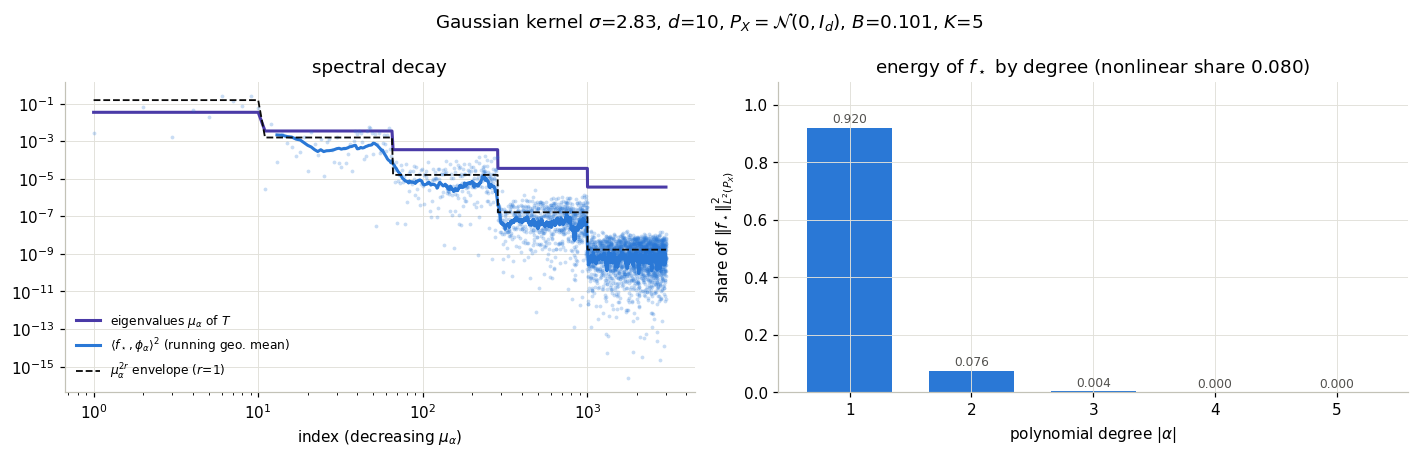

In [31]:
nz = f_coef != 0                                    # the constant mode is excluded from f*
mu_sorted, coef2 = mu_modes[nz], f_coef[nz] ** 2   # modes are listed by degree, so mu is non-increasing
j = np.arange(1, len(mu_sorted) + 1)
envelope = mu_sorted ** (2 * r_source) / ((len(alphas) - 1) * f_scale**2)   # E <f*, phi_alpha>^2
win = 25
running = np.exp(np.convolve(np.log(coef2 + 1e-300), np.ones(win) / win, mode="same"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.loglog(j, mu_sorted, color="#4a3aa7", label=r"eigenvalues $\mu_\alpha$ of $T$")
ax.loglog(j, coef2, "o", ms=2.5, color="#2a78d6", alpha=0.25, mec="none")
ax.loglog(j[win // 2:-win // 2], running[win // 2:-win // 2], color="#2a78d6",
          label=r"$\langle f_\star,\phi_\alpha\rangle^2$ (running geo. mean)")
ax.loglog(j, envelope, "--", color="#0b0b0b", lw=1.2, label=fr"$\mu_\alpha^{{2r}}$ envelope ($r$={r_source:g})")
ax.set_xlabel(r"index (decreasing $\mu_\alpha$)"); ax.set_title("spectral decay")
ax.legend(fontsize=8)

ax = axes[1]
degs = np.arange(1, K_deg + 1)
ax.bar(degs, deg_share[1:], color="#2a78d6", width=0.7)
for k, s in zip(degs, deg_share[1:]):
    ax.annotate(f"{s:.3f}", (k, s), textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8, color="#52514e")
ax.set_xticks(degs); ax.set_xlabel(r"polynomial degree $|\alpha|$")
ax.set_ylabel(r"share of $\|f_\star\|^2_{L^2(P_X)}$"); ax.set_ylim(0, 1.08)
ax.set_title(fr"energy of $f_\star$ by degree (nonlinear share {1 - deg_share[1]:.3f})")
plt.suptitle(fr"Gaussian kernel $\sigma$={sigma:.3g}, $d$={d}, $P_X=\mathcal{{N}}(0,I_d)$, $B$={B_h:.3f}, $K$={K_deg}")
plt.tight_layout(); plt.show()


## 2. Random Fourier features, adversaries and robust second-moment estimators

The RFF map (eq. rff) with $\|\Phi(x)\|_2^2\le2$ and the bound-filter / geometric median-of-means (GMoM) estimators
are taken from `random_features_test.ipynb`, here applied only to the second moment $M$ (ITGD handles the responses itself).

Adversaries replace complete pairs $(x,y)$ **in input space**, $|O|=\lfloor\epsilon n\rfloor$; the features of every point,
clean or corrupted, are then computed as $z=\Phi(x)$. The adversary sees the full sample and $f_\star$, but not the
random feature map $(W,b)$.

* `label_flip` — keep $x_i$, set $y_i\leftarrow-y_i$.
* `cluster` — a tight cluster (std $0.05$) at the sample point $x_0$ with the largest $|f_\star|$, with $y=-\mathrm{sign}(f_\star(x_0))B_y$.
* `tail` — $x$ uniform on the sphere of radius $3\sqrt d$ (far in the tails of $P_X$), $y=B_y$.
* `gross` — $x$ uniform on the sphere of radius $100\sqrt d$, $y=100B_y$.

Since the noise is Gaussian, $Y$ is not bounded; the adversaries use $B_y=\sup|f_\star|+3s$ as a nominal bound.

Because corrupted covariates also pass through $\Phi$, corrupted features satisfy $\|z\|_2\le\sqrt2$ too: the bound
filter removes nothing and `bound` reduces to the empirical second moment. Robustness of $\widehat M$ has to come from GMoM.


In [32]:
def sample_rff(d, m, sigma, rng):
    # Draw the random feature map parameters (omega_j, b_j) for the Gaussian kernel of width sigma.
    W = rng.normal(0.0, 1.0 / sigma, size=(m, d))
    b = rng.uniform(0.0, 2 * np.pi, size=m)
    return W, b


def rff(X, W, b):
    # Phi(x) = sqrt(2/m) cos(W x + b), one row per point.
    return np.sqrt(2.0 / W.shape[0]) * np.cos(X @ W.T + b)


ATTACKS = ["label_flip", "cluster", "tail", "gross"]


def corrupt_inputs(X, y, epsilon, attack, rng, y_bound):
    # Strong contamination of complete pairs (x, y) in input space; features are computed afterwards.
    n, d = X.shape
    n_bad = int(np.floor(epsilon * n))
    Xc, yc = X.copy(), y.copy()
    if n_bad == 0:
        return Xc, yc, np.zeros(0, dtype=int)
    idx = rng.choice(n, n_bad, replace=False)
    u = rng.normal(size=(n_bad, d))
    u /= np.linalg.norm(u, axis=1, keepdims=True)   # random unit directions
    if attack == "label_flip":
        yc[idx] = -y[idx]
    elif attack == "cluster":
        f_X = f_star(X)                               # omniscient adversary: knows f*
        j = np.argmax(np.abs(f_X))
        Xc[idx] = X[j] + 0.05 * rng.normal(size=(n_bad, d))
        yc[idx] = -np.sign(f_X[j]) * y_bound
    elif attack == "tail":
        Xc[idx] = 3 * np.sqrt(d) * u
        yc[idx] = y_bound
    elif attack == "gross":
        Xc[idx] = 100 * np.sqrt(d) * u
        yc[idx] = 100 * y_bound
    else:
        raise ValueError(attack)
    return Xc, yc, idx


def geometric_median_gram(H, max_iter=500, tol=1e-10):
    # Weiszfeld iteration for the geometric median of points P_1..P_k, given only their Gram matrix H[b, c] = <P_b, P_c>.
    # The iterate stays a convex combination g = sum_b lam_b P_b, so every distance is a quadratic form in H.
    # Returns the weights lam.
    lam = np.full(len(H), 1.0 / len(H))
    for _ in range(max_iter):
        H_lam = H @ lam
        dist = np.sqrt(np.maximum(np.diag(H) - 2 * H_lam + lam @ H_lam, 0))   # ||P_b - g||
        w = 1.0 / np.maximum(dist, 1e-12)
        lam_new = w / w.sum()
        step = lam_new - lam
        lam = lam_new
        if np.sqrt(max(step @ H @ step, 0)) <= tol * max(1.0, np.sqrt(max(lam @ H @ lam, 0))):
            break
    return lam


def second_moment(Z, epsilon, method, z_bound, rng):
    # Estimate M = E[Z Z^T] from (possibly corrupted) features.
    #   empirical : plain average (nonrobust)
    #   bound     : drop ||z|| > z_bound (clean RFFs satisfy it deterministically), then average
    #   gmom      : bound filter, then geometric median-of-means over k = 2 floor(eps n) + 1 blocks
    if method == "empirical":
        return Z.T @ Z / len(Z)
    n_total = len(Z)
    Z = Z[np.sum(Z**2, axis=1) <= z_bound**2 * (1 + 1e-9)]
    if method == "bound":
        return Z.T @ Z / len(Z)
    if method == "gmom":
        n, m = Z.shape
        n_bad = int(np.floor(epsilon * n_total))
        k = int(min(2 * n_bad + 1, n // 2)) if n_bad > 0 else 1
        blocks = np.array_split(rng.permutation(n), k)
        # Block moments M_b = Z_b^T Z_b / |b| are never formed: <M_b, M_c>_F = ||Z_b Z_c^T||_F^2 / (|b||c|), so their
        # Gram matrix is P (Z Z^T)^2 P^T with P[b, i] = 1/|b| for i in block b. Memory O(n^2 + kn) instead of O(k m^2).
        P = np.zeros((k, n))
        for b, B in enumerate(blocks):
            P[b, B] = 1.0 / len(B)
        H = P @ (Z @ Z.T) ** 2 @ P.T
        p = geometric_median_gram(H) @ P       # M_hat = sum_b lam_b M_b = sum_i p_i z_i z_i^T
        return (Z * p[:, None]).T @ Z
    raise ValueError(method)


def ridge(Z, y, lam):
    n, m = Z.shape
    return np.linalg.solve(Z.T @ Z / n + lam * np.eye(m), Z.T @ y / n)


z_bound = np.sqrt(2.0)
y_bound = np.max(np.abs(f_eval)) + 3 * noise

### 2a. Ridge parameter $\lambda=c/\sqrt n$ by cross-validation

Rudi & Rosasco (2017) take $\lambda\asymp1/\sqrt n$, for which $m\asymp\sqrt n\log n$ random features match exact KRR; the
constant $c$ is left open. It is chosen by $K$-fold cross-validation of exact clean KRR on an independent clean sample,
with $\lambda=c/\sqrt{n_{\rm fit}}$ on each training fold ($n_{\rm fit}$ = training-fold size) so that $c$ transfers to the full $n$.
One eigendecomposition $K_{\rm fit}=U\,\mathrm{diag}(\mu)\,U^\top$ per fold serves the whole grid:
$\bm\alpha=U\,\mathrm{diag}\big(1/(\mu+n_{\rm fit}\lambda)\big)\,U^\top\bm y$.

The CV curve estimates $\|\widehat f_\lambda-f_\star\|^2_{L^2(P_X)}+s^2$, so it is compared with the oracle error
$\|\widehat f_\lambda-f_\star\|^2_{L^2(P_X)}+s^2$ of KRR fit on the whole sample (available here only because $f_\star$ is known).
Choosing $c$ on clean data is an oracle choice: it fixes the regularization of the reference solution, not something the
robust pipeline learns from contaminated data.


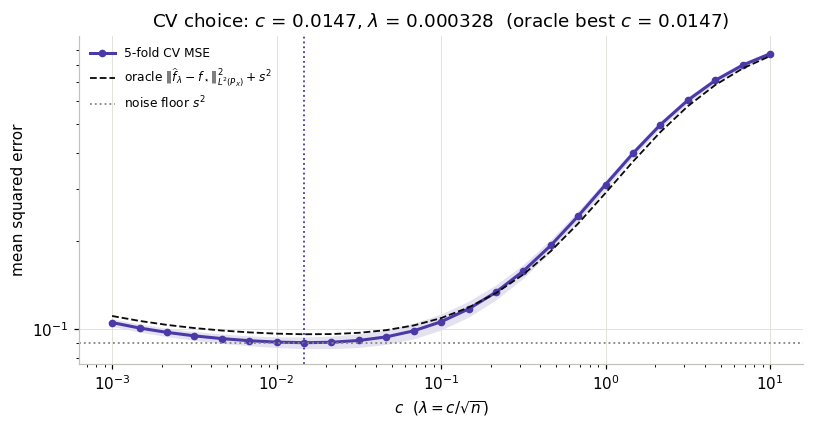

c = 0.01468,  lambda = c/sqrt(n) = 0.0003282


In [33]:
n = 2000                           # sample size
C_GRID = np.logspace(-3, 1, 25)    # candidate constants c in lambda = c / sqrt(n)
N_FOLDS = 5


def cv_lambda_constant(X, y, c_grid, n_folds, rng):
    # K-fold CV for exact KRR with lambda = c / sqrt(n_fit), n_fit = training-fold size, so c transfers to the full n.
    # One eigendecomposition per fold serves the whole grid: alpha = U diag(1 / (mu + n_fit lambda)) U^T y.
    folds = np.array_split(rng.permutation(len(X)), n_folds)
    mse = np.zeros((n_folds, len(c_grid)))
    for f, val in enumerate(folds):
        fit = np.setdiff1d(np.arange(len(X)), val)
        mu, U = np.linalg.eigh(gaussian_kernel(X[fit], X[fit], sigma))
        Uy = U.T @ y[fit]
        K_val = gaussian_kernel(X[val], X[fit], sigma)
        for j, c in enumerate(c_grid):
            alpha = U @ (Uy / (mu + len(fit) * c / np.sqrt(len(fit))))
            mse[f, j] = np.mean((K_val @ alpha - y[val]) ** 2)
    return mse.mean(0), mse.std(0) / np.sqrt(n_folds)


X_cv, y_cv = sample_xy(n, rng)     # independent clean sample, used only to choose c
cv_mse, cv_se = cv_lambda_constant(X_cv, y_cv, C_GRID, N_FOLDS, rng)
C_LAM = C_GRID[np.argmin(cv_mse)]
lam = C_LAM / np.sqrt(n)           # ridge parameter, lambda = c / sqrt(n)

# oracle check: ||f_lambda - f*||^2 + s^2 for KRR on the whole CV sample (first 5000 points of X_eval)
mu, U = np.linalg.eigh(gaussian_kernel(X_cv, X_cv, sigma))
Uy = U.T @ y_cv
K_ev = gaussian_kernel(X_eval[:5000], X_cv, sigma)
oracle = np.array([np.mean((K_ev @ (U @ (Uy / (mu + n * c / np.sqrt(n)))) - f_eval[:5000]) ** 2) for c in C_GRID]) + noise**2

fig, ax = plt.subplots(figsize=(7.5, 4))
color = STYLE["clean KRR"][0]
ax.plot(C_GRID, cv_mse, "o-", color=color, ms=4, label=f"{N_FOLDS}-fold CV MSE")
ax.fill_between(C_GRID, cv_mse - cv_se, cv_mse + cv_se, color=color, alpha=0.15, lw=0)
ax.plot(C_GRID, oracle, "--", color="#0b0b0b", lw=1.2, label=r"oracle $\|\widehat f_\lambda-f_\star\|^2_{L^2(P_X)}+s^2$")
ax.axhline(noise**2, color="#898781", ls=":", lw=1.2, label=r"noise floor $s^2$")
ax.axvline(C_LAM, color=color, ls=":", lw=1.2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$c$  ($\lambda=c/\sqrt{n}$)"); ax.set_ylabel("mean squared error")
ax.set_title(fr"CV choice: $c$ = {C_LAM:.3g}, $\lambda$ = {lam:.3g}  (oracle best $c$ = {C_GRID[np.argmin(oracle)]:.3g})")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"c = {C_LAM:.4g},  lambda = c/sqrt(n) = {lam:.4g}")


## 3. The split + ITGD estimator

**Whitening scale.** `itgd_linear` whitens with $\Sigma^{-1/2}$ and runs gradient descent (with covariate filtering and
per-iteration hard thresholding) in the whitened coordinates. The RFF second moment has eigenvalues far below any
achievable robust estimation error, so whitening by $\widehat M^{-1/2}$ itself is exactly the unstable full whitening the
prospectus warns against (§Spectral resolution). We therefore pass $\Sigma=\widehat M_A+\lambda_wI$: directions with
$\widehat\mu_j\ll\lambda_w$ are *not* whitened.

**Regularization.** `itgd_linear` has no explicit ridge penalty; it is regularized by early stopping. After $T$ steps of
size $\eta$ from zero, the filter on an eigen-direction with whitened curvature $h_j=\mu_j/(\mu_j+\lambda_w)$ is
$1-(1-\eta h_j)^T\approx h_j/(h_j+1/(\eta T))\approx \mu_j/(\mu_j+\lambda_w/(\eta T))$, i.e. approximately ridge with
$\lambda_{\rm eff}=\lambda_w/(\eta T)$. We set $\lambda_w=\lambda\,\eta\,T$ so that ITGD targets the same $\lambda$ as the KRR comparator.

**Corruption level given to ITGD.** The adversary corrupts $\lfloor\epsilon n\rfloor$ pairs *before* the random split, so
half $B$ receives a hypergeometric number of them: its outlier fraction has mean $\epsilon$ and standard deviation
$\approx\sqrt{\epsilon/n}$. If ITGD trims exactly an $\epsilon$ fraction, then on about half of the draws a few outliers survive
the trimming, and with the `gross` attack a single survivor dominates the fit. ITGD is therefore given
$\epsilon_B=\epsilon+3\sqrt{\epsilon/n}$.

**$\epsilon$ floor.** $\epsilon_B$ is floored at $0.005$. At $\epsilon=0$ the covariate filter's stopping rule
$\|\mathrm{Cov}-I\|<C\epsilon$ can never fire, so it runs all `max_epochs` without changing any weight; for very small
$\epsilon>0$ (e.g. $10^{-3}$) its 1-D filter step receives an empty index set and raises. With $C=500$, $\epsilon=0.005$
makes the filter return immediately on clean whitened data and trims only 0.5% of half $B$.

**Corrupted KRR baseline.** Since the corruption happens in input space, `corrupted KRR` is exact Gaussian KRR on the
contaminated pairs $(x^{\rm corr}_i,y^{\rm corr}_i)$, the nonrobust kernel method that `nonrobust RFF` approximates.

**Hypotheses compared** (all evaluated as functions on `X_eval`):

| name | data | description |
|---|---|---|
| `clean KRR` | clean, all $n$ | exact Gaussian KRR, `KernelRidge(alpha=nλ)` — the reference solution |
| `corrupted KRR` | corrupted, all $n$ | exact Gaussian KRR on the contaminated sample — nonrobust kernel baseline |
| `oracle clean RFF` | clean, all $n$ | RFF ridge on uncorrupted features |
| `nonrobust RFF` | corrupted, all $n$ | RFF ridge on the contaminated sample |
| `ITGD (robust M)` | corrupted, $A$ / $B$ | **the proposed pipeline**: robust $\widehat M$ on $A$, ITGD on $B$ |
| `ITGD (empirical M)` | corrupted, $A$ / $B$ | ablation: nonrobust $\widehat M$ on $A$ |
| `ITGD (oracle M)` | corrupted, $B$ | ablation: population $M$ (isolates the covariance-estimation error) |

In [34]:
m = int(np.ceil(np.sqrt(n) * np.log(n)))   # number of random features, m ~ sqrt(n) log n
COV_METHOD = "gmom"                # robust M on half A: "gmom" or "bound"
ETA, T_ITGD = 1.0, 50              # ITGD step size and number of iterations
LAM_W = lam * ETA * T_ITGD         # whitening floor, so that lambda_eff = LAM_W / (ETA * T) = lam
EPS_ITGD_MIN = 0.005               # epsilon floor passed to ITGD (see note above)


def itgd_epsilon(epsilon):
    # corruption level assumed by ITGD on half B: split slack + floor (see note above)
    return max(epsilon + 3 * np.sqrt(epsilon / n), EPS_ITGD_MIN)


def fit_itgd(Z_B, y_B, M_hat, epsilon):
    Sigma = M_hat + LAM_W * np.eye(len(M_hat))
    beta, hist = itgd_linear(Z_B, y_B, Sigma, itgd_epsilon(epsilon), eta=ETA, T=T_ITGD)
    return beta


def run_trial(epsilon, attack, rng, trial=0, return_predictor=False):
    # --- clean sample, feature map, population moments (Monte Carlo on X_eval) ---
    X, y = sample_xy(n, rng)
    W, b = sample_rff(d, m, sigma, rng)
    Z_eval = rff(X_eval, W, b)
    M_pop = Z_eval.T @ Z_eval / len(Z_eval)

    # --- adversary replaces an epsilon fraction of (x, y) pairs in input space, then all points are featurized ---
    Xo, yo, bad = corrupt_inputs(X, y, epsilon, attack, rng, y_bound)
    Z, Zo = rff(X, W, b), rff(Xo, W, b)
    is_bad = np.zeros(n, dtype=bool); is_bad[bad] = True

    # --- sample split: A -> robust second moment, B -> ITGD regression ---
    perm = rng.permutation(n)
    A, B = perm[: n // 2], perm[n // 2:]
    M_rob = second_moment(Zo[A], epsilon, COV_METHOD, z_bound, rng)
    M_emp = second_moment(Zo[A], epsilon, "empirical", z_bound, rng)

    krr = KernelRidge(alpha=n * lam, kernel="rbf", gamma=1 / (2 * sigma**2)).fit(X, y)
    krr_bad = KernelRidge(alpha=n * lam, kernel="rbf", gamma=1 / (2 * sigma**2)).fit(Xo, yo)  # contaminated sample
    betas = {
        "oracle clean RFF":   ridge(Z, y, lam),
        "nonrobust RFF":      ridge(Zo, yo, lam),
        "ITGD (robust M)":    fit_itgd(Zo[B], yo[B], M_rob, epsilon),
        "ITGD (empirical M)": fit_itgd(Zo[B], yo[B], M_emp, epsilon),
        "ITGD (oracle M)":    fit_itgd(Zo[B], yo[B], M_pop, epsilon),
    }

    def predict(Xq):
        # every hypothesis evaluated at the query points Xq
        Zq = rff(Xq, W, b)
        return {"clean KRR": krr.predict(Xq), "corrupted KRR": krr_bad.predict(Xq),
                **{name: Zq @ beta for name, beta in betas.items()}}

    preds = {"clean KRR": krr.predict(X_eval), "corrupted KRR": krr_bad.predict(X_eval)}
    preds.update({name: Z_eval @ beta for name, beta in betas.items()})

    # fraction of the outliers in B that ITGD's final trimmed set still keeps
    beta_rob = betas["ITGD (robust M)"]
    k = int(np.ceil(len(B) * (1 - itgd_epsilon(epsilon))))
    kept = np.argsort((Zo[B] @ beta_rob - yo[B]) ** 2)[:k]
    n_bad_B = is_bad[B].sum()
    outliers_kept = is_bad[B][kept].sum() / n_bad_B if n_bad_B else np.nan

    f_std = np.std(f_eval)                                   # std(f*) under P_X, estimated on X_eval
    naive_err = l2_dist(preds["corrupted KRR"], f_eval)       # naive KRR = exact KRR on the corrupted sample
    rows = []
    for name, p in preds.items():
        M_used = {"ITGD (robust M)": M_rob, "ITGD (empirical M)": M_emp}.get(name)
        rows.append(dict(trial=trial, epsilon=epsilon, attack=attack, hypothesis=name,
                         dist_to_krr=l2_dist(p, preds["clean KRR"]),     # ||f_hat - f_KRR||_{L2(P_X)}
                         dist_to_fstar=l2_dist(p, f_eval),              # ||f_hat - f*||_{L2(P_X)}
                         rel_std=l2_dist(p, f_eval) / f_std,            # ||f_hat - f*|| / std(f*)
                         rel_naive=l2_dist(p, f_eval) / naive_err,      # ||f_hat - f*|| / ||f_naive - f*||
                         op_err=np.linalg.norm(M_used - M_pop, 2) if M_used is not None else np.nan,
                         outliers_kept=outliers_kept if name == "ITGD (robust M)" else np.nan))
    return (rows, predict) if return_predictor else rows


def plot_lines(ax, df, x, y, names, logy=True):
    for name in names:
        g = df[df.hypothesis == name].groupby(x)[y]
        mean, std = g.mean(), g.std().fillna(0)
        if logy:  # exact zeros (e.g. corrupted KRR vs clean KRR at epsilon = 0) cannot be drawn on a log axis
            mean, std = mean[mean > 0], std[mean > 0]
        color, marker, ls = STYLE[name]
        ax.plot(mean.index, mean.values, ls=ls, marker=marker, color=color, label=name)
        lower = np.maximum(mean - std, 0.2 * mean) if logy else mean - std     # keep the band visible on log axes
        ax.fill_between(mean.index, lower, mean + std, color=color, alpha=0.12, lw=0)
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel(x)

### 3a. Sanity check at $\epsilon=0$

With no contamination, every hypothesis should be close to clean KRR. The ITGD variants use only half the sample for
regression and (by construction) trim only 0.5% at $\epsilon=0$, so they should sit near `oracle clean RFF`, slightly worse.

In [35]:
rows = []
for t in range(3):
    rows += run_trial(0.0, "label_flip", rng, t)
(pd.DataFrame(rows).groupby("hypothesis")[["dist_to_krr", "dist_to_fstar"]].mean()
 .reindex(list(STYLE)).round(4))

,dist_to_krr,dist_to_fstar
hypothesis,,
clean KRR,0.0000,0.0847
corrupted KRR,0.0000,0.0847
oracle clean RFF,0.1167,0.1421
nonrobust RFF,0.1167,0.1421
ITGD (robust M),0.1527,0.1692
ITGD (empirical M),0.1527,0.1692
ITGD (oracle M),0.1525,0.1691


## 4. Hypotheses vs. clean KRR as $\epsilon$ varies

One row per adversary in `ATTACKS`. Both panels show the error to the truth $\|\widehat f-f_\star\|_{L^2(P_X)}$, relative to
a reference:

* Left: relative to $\mathrm{std}(f_\star)$, the error of the best constant predictor. $1$ means no better than predicting the mean.
* Right: relative to the naive KRR $\widehat f_{\rm naive}$, exact KRR fit on the corrupted sample (`corrupted KRR`), which is
  $1$ by definition (dotted line). Below $1$ means the method beats running KRR on the contaminated data.
Bands are ±1 std over trials.

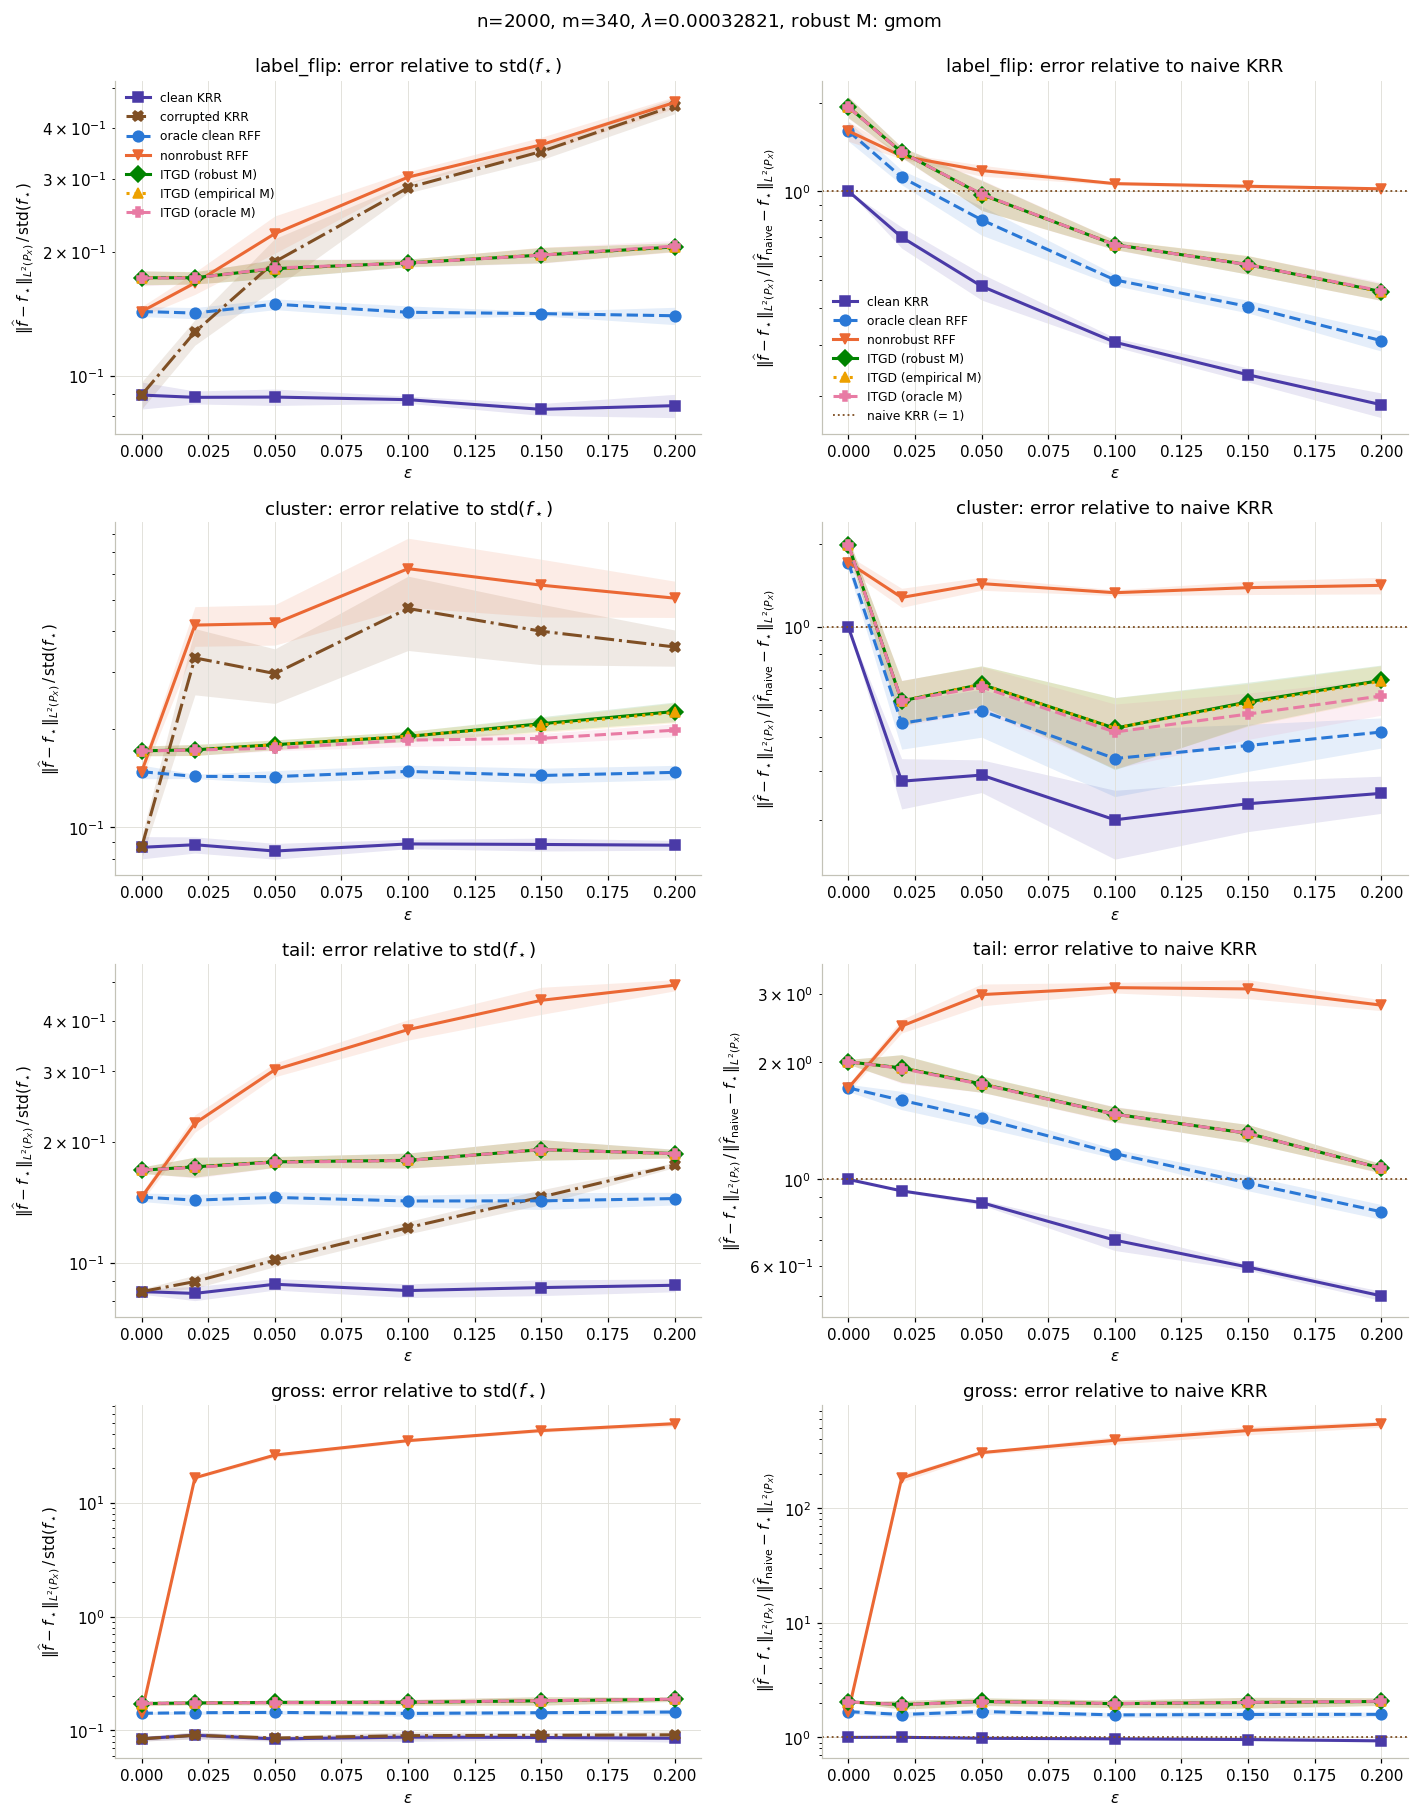

hypothesis          clean KRR  corrupted KRR  oracle clean RFF  nonrobust RFF  \
attack     epsilon                                                              
cluster    0.00        1.0000            1.0            1.7131         1.7131   
           0.02        0.2761            1.0            0.4479         1.2800   
           0.05        0.2906            1.0            0.4965         1.4368   
           0.10        0.2000            1.0            0.3336         1.3315   
           0.15        0.2288            1.0            0.3719         1.3891   
           0.20        0.2495            1.0            0.4163         1.4160   
gross      0.00        1.0000            1.0            1.6773         1.6773   
           0.02        1.0018            1.0            1.5833       183.1215   
           0.05        0.9819            1.0            1.6808       304.8882   
           0.10        0.9704            1.0            1.5704       390.6781   
           0.15        0.9577            1.0            1.5839       475.2639   
           0.20        0.9331            1.0            1.5884       540.3165   
label_flip 0.00        1.0000            1.0            1.6020         1.6020   
           0.02        0.6970            1.0            1.1150         1.3158   
           0.05        0.4746            1.0            0.7986         1.1751   
           0.10        0.3060            1.0            0.4987         1.0605   
           0.15        0.2371            1.0            0.4048         1.0386   
           0.20        0.1875            1.0            0.3097         1.0182   
tail       0.00        1.0000            1.0            1.7197         1.7197   
           0.02        0.9342            1.0            1.5979         2.4808   
           0.05        0.8715            1.0            1.4357         2.9890   
           0.10        0.6976            1.0            1.1655         3.1147   
           0.15        0.5947            1.0            0.9790         3.0917   
           0.20        0.5016            1.0            0.8253         2.8080   

hypothesis          ITGD (robust M)  ITGD (empirical M)  ITGD (oracle M)  
attack     epsilon                                                        
cluster    0.00              1.9865              1.9865           1.9843  
           0.02              0.5393              0.5393           0.5391  
           0.05              0.6198              0.6196           0.6061  
           0.10              0.4296              0.4301           0.4162  
           0.15              0.5356              0.5305           0.4837  
           0.20              0.6407              0.6363           0.5625  
gross      0.00              2.0387              2.0387           2.0418  
           0.02              1.9323              1.9312           1.9324  
           0.05              2.0578              2.0557           2.0498  
           0.10              1.9678              1.9694           1.9735  
           0.15              2.0162              2.0158           2.0204  
           0.20              2.0581              2.0605           2.0662  
label_flip 0.00              1.9349              1.9349           1.9317  
           0.02              1.3572              1.3576           1.3553  
           0.05              0.9738              0.9737           0.9771  
           0.10              0.6571              0.6576           0.6565  
           0.15              0.5618              0.5629           0.5615  
           0.20              0.4550              0.4539           0.4572  
tail       0.00              2.0066              2.0066           2.0087  
           0.02              1.9356              1.9353           1.9291  
           0.05              1.7608              1.7609           1.7561  
           0.10              1.4721              1.4708           1.4710  
           0.15              1.3133              1.3139           1.3140  
           0.20   

In [36]:
eps_grid = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2]
N_TRIALS = 5

rows = []
for attack in ATTACKS:
    for eps in eps_grid:
        for t in range(N_TRIALS):
            rows += run_trial(eps, attack, rng, t)
df_eps = pd.DataFrame(rows)

fig, axes = plt.subplots(len(ATTACKS), 2, figsize=(13, 4.2 * len(ATTACKS)))
for (ax_std, ax_nv), attack in zip(axes, ATTACKS):
    df_a = df_eps[df_eps.attack == attack]
    plot_lines(ax_std, df_a, "epsilon", "rel_std", list(STYLE))
    ax_std.set_ylabel(r"$\|\widehat f-f_\star\|_{L^2(P_X)}\,/\,\mathrm{std}(f_\star)$")
    ax_std.set_title(fr"{attack}: error relative to std$(f_\star)$")
    plot_lines(ax_nv, df_a, "epsilon", "rel_naive", [h for h in STYLE if h != "corrupted KRR"])
    ax_nv.axhline(1.0, color=STYLE["corrupted KRR"][0], ls=":", lw=1.2, label="naive KRR (= 1)")
    ax_nv.set_ylabel(r"$\|\widehat f-f_\star\|_{L^2(P_X)}\,/\,\|\widehat f_{\rm naive}-f_\star\|_{L^2(P_X)}$")
    ax_nv.set_title(f"{attack}: error relative to naive KRR")
    for ax in (ax_std, ax_nv):
        ax.set_xlabel(r"$\epsilon$")
axes[0, 0].legend(fontsize=8); axes[0, 1].legend(fontsize=8)
plt.suptitle(fr"n={n}, m={m}, $\lambda$={lam:g}, robust M: {COV_METHOD}")
plt.tight_layout(rect=(0, 0, 1, 0.985)); plt.show()

(df_eps.groupby(["attack", "epsilon", "hypothesis"]).rel_naive.mean()
 .unstack("hypothesis").reindex(columns=list(STYLE)).round(4))


### 4a. Diagnostics: covariance estimation on half $A$ and trimming on half $B$

Left: $\|\widehat M-M\|_{op}$ for the robust and the empirical estimate from half $A$ (compare with the whitening floor
$\lambda_w$: when the error exceeds it, the whitened geometry is distorted). Right: the fraction of half-$B$ outliers
that remain in ITGD's final trimmed set (0 = every outlier discarded).

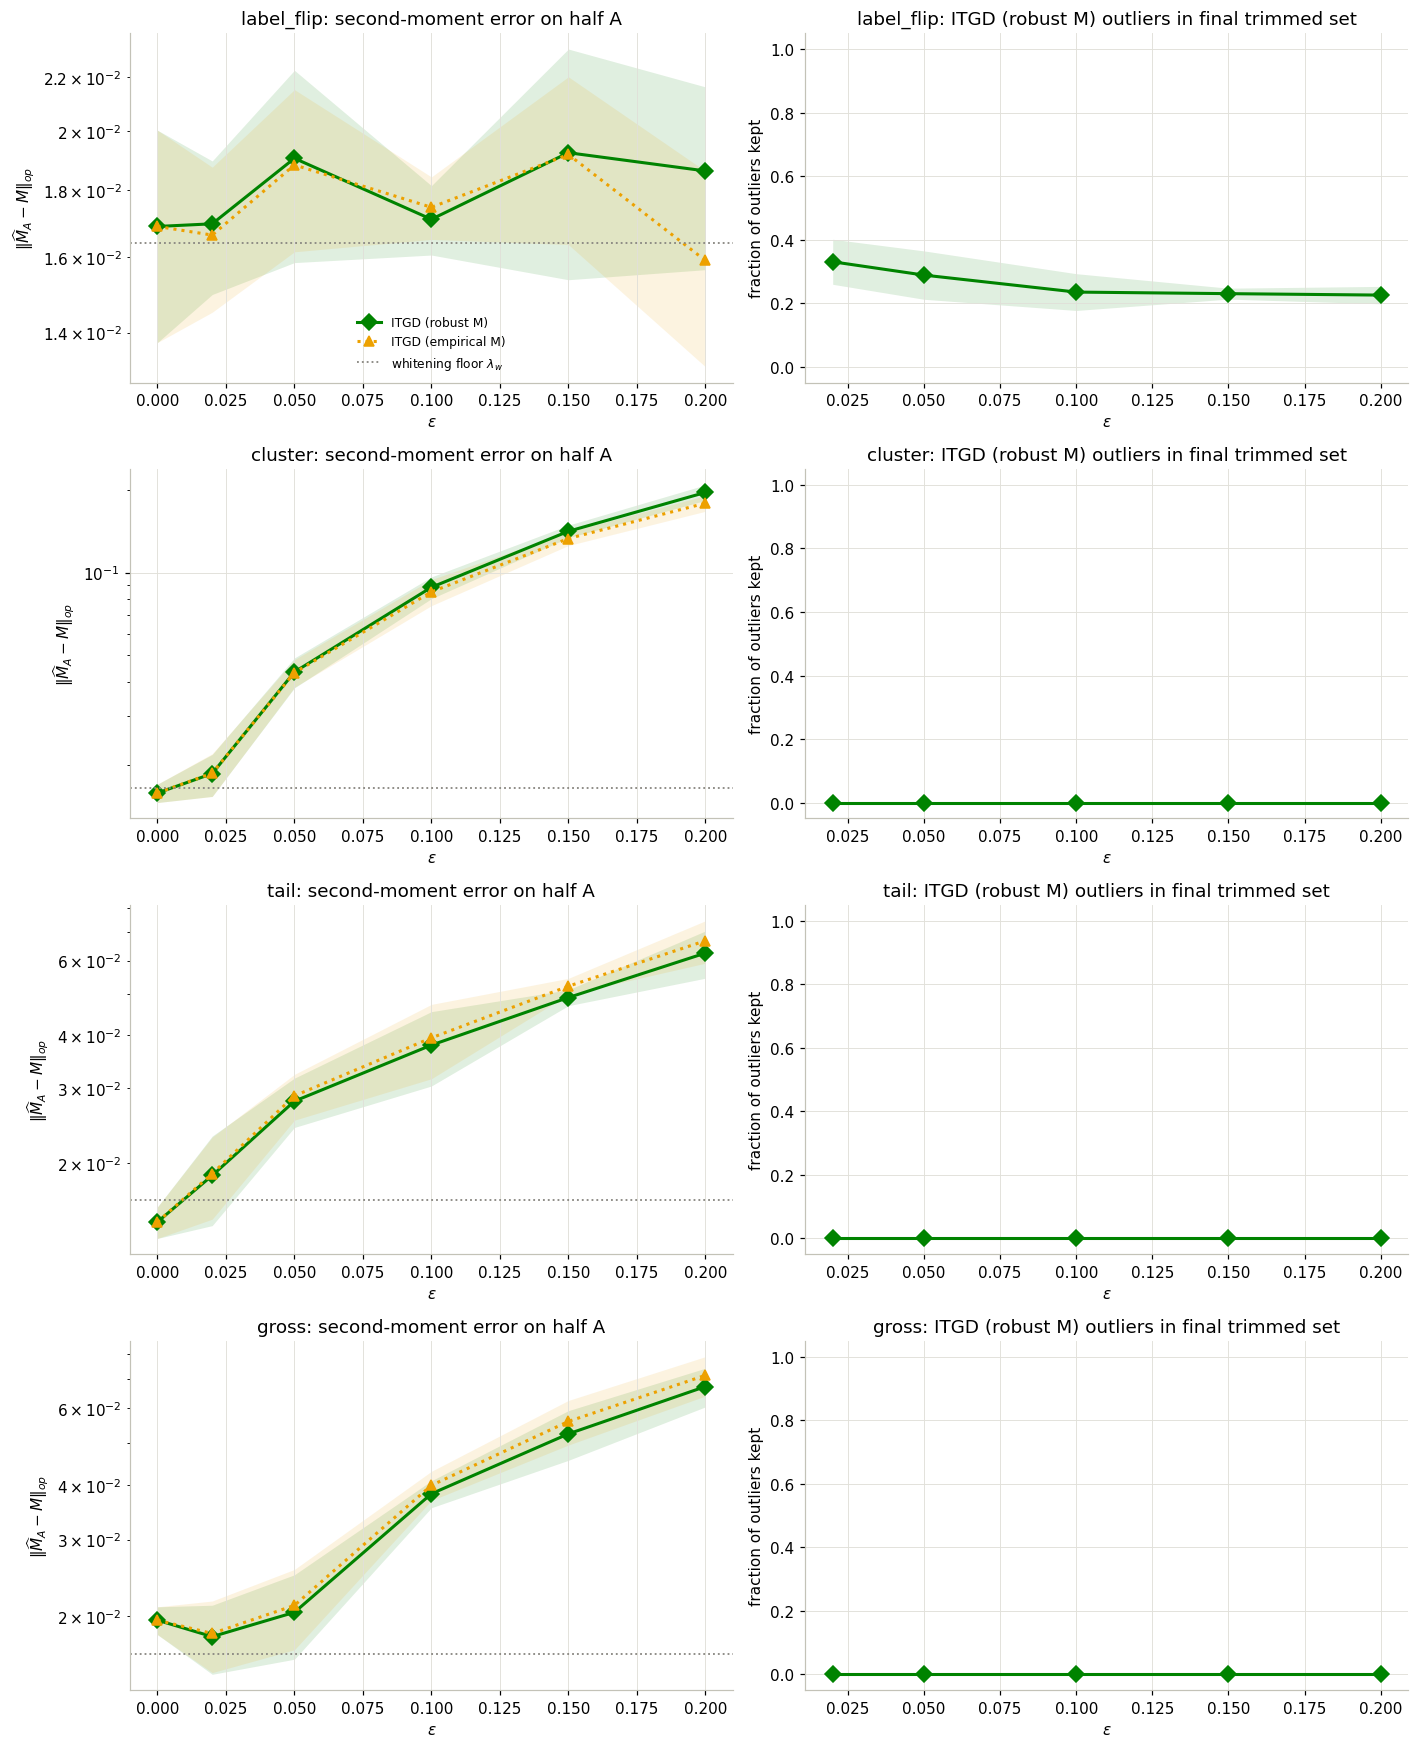

In [37]:
fig, axes = plt.subplots(len(ATTACKS), 2, figsize=(13, 4 * len(ATTACKS)))
for (ax_op, ax_kept), attack in zip(axes, ATTACKS):
    df_a = df_eps[df_eps.attack == attack]
    plot_lines(ax_op, df_a, "epsilon", "op_err", ["ITGD (robust M)", "ITGD (empirical M)"])
    ax_op.axhline(LAM_W, color="#898781", ls=":", lw=1.2, label=r"whitening floor $\lambda_w$")
    ax_op.set_ylabel(r"$\|\widehat M_A-M\|_{op}$"); ax_op.set_xlabel(r"$\epsilon$")
    ax_op.set_title(f"{attack}: second-moment error on half A")
    ok = df_a[(df_a.hypothesis == "ITGD (robust M)") & (df_a.epsilon > 0)]
    plot_lines(ax_kept, ok, "epsilon", "outliers_kept", ["ITGD (robust M)"], logy=False)
    ax_kept.set_ylim(-0.05, 1.05); ax_kept.set_xlabel(r"$\epsilon$")
    ax_kept.set_ylabel("fraction of outliers kept")
    ax_kept.set_title(f"{attack}: ITGD (robust M) outliers in final trimmed set")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()


## 5. What the hypotheses look like

A 1-D slice of each hypothesis along a random unit direction $u$, $x=tu$ for $t\in[-3,3]$, for one draw at three
contamination levels (adversary `ATTACK`). The dashed black curve is $f_\star$.

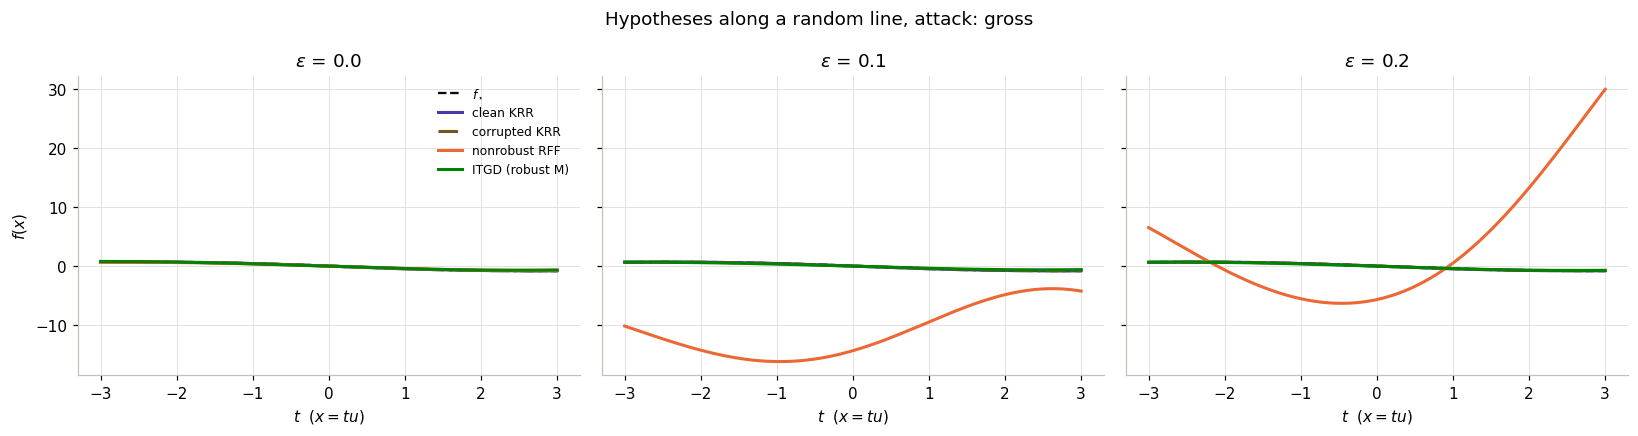

In [38]:
ATTACK = "gross"
u = rng.normal(size=d); u /= np.linalg.norm(u)
ts = np.linspace(-3, 3, 200)
X_line = ts[:, None] * u[None, :]
show = ["clean KRR", "corrupted KRR", "nonrobust RFF", "ITGD (robust M)"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, eps in zip(axes, [0.0, 0.1, 0.2]):
    _, predict = run_trial(eps, ATTACK, np.random.default_rng(SEED + 1), return_predictor=True)
    preds = predict(X_line)
    ax.plot(ts, f_star(X_line), "--", color="#0b0b0b", lw=1.5, label=r"$f_\star$")
    for name in show:
        color, _, ls = STYLE[name]
        ax.plot(ts, preds[name], ls=ls, color=color, label=name)
    ax.set_title(fr"$\epsilon$ = {eps}"); ax.set_xlabel(r"$t$  ($x=tu$)")
axes[0].set_ylabel(r"$f(x)$"); axes[0].legend(fontsize=8)
plt.suptitle(f"Hypotheses along a random line, attack: {ATTACK}")
plt.tight_layout(); plt.show()

## 6. Sensitivity to the adversary

Distance to clean KRR at $\epsilon=0.1$ for every attack.

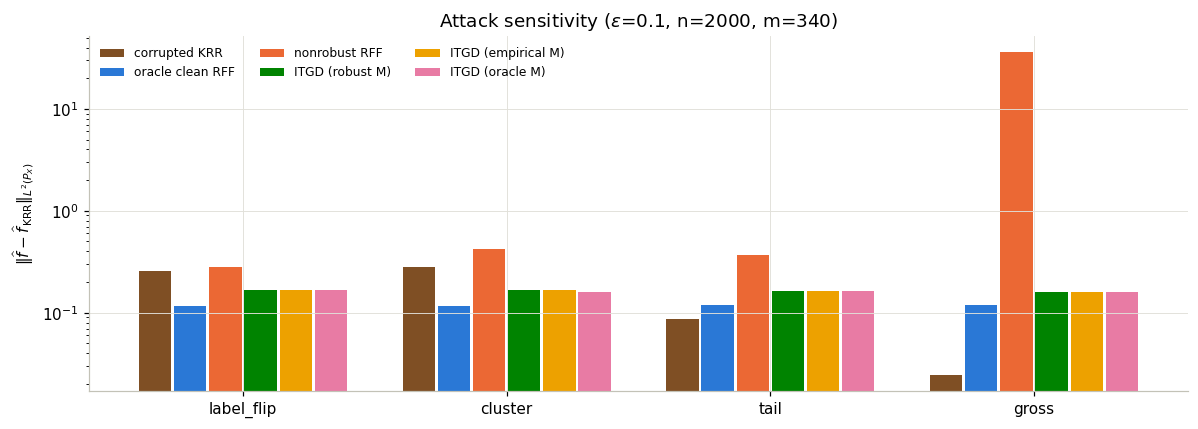

hypothesis,corrupted KRR,oracle clean RFF,nonrobust RFF,ITGD (robust M),ITGD (empirical M),ITGD (oracle M)
attack,,,,,,
cluster,0.2786,0.1152,0.4173,0.1681,0.1678,0.1586
gross,0.0245,0.1193,35.9069,0.1601,0.1603,0.1601
label_flip,0.2579,0.1170,0.2811,0.1684,0.1683,0.1685
tail,0.0861,0.1180,0.3726,0.1625,0.1624,0.1622


In [39]:
eps_att = 0.1
rows = []
for attack in ATTACKS:
    for t in range(N_TRIALS):
        rows += run_trial(eps_att, attack, rng, t)
df_att = pd.DataFrame(rows)

names = [h for h in STYLE if h != "clean KRR"]
fig, ax = plt.subplots(figsize=(11, 4))
width = 0.8 / len(names)
x = np.arange(len(ATTACKS))
for k, name in enumerate(names):
    vals = [df_att[(df_att.attack == a) & (df_att.hypothesis == name)].dist_to_krr.mean() for a in ATTACKS]
    ax.bar(x + (k - len(names) / 2 + 0.5) * width, vals, width * 0.92, color=STYLE[name][0], label=name)
ax.set_xticks(x, ATTACKS); ax.set_yscale("log")
ax.set_ylabel(r"$\|\widehat f-\widehat f_{\rm KRR}\|_{L^2(P_X)}$")
ax.set_title(fr"Attack sensitivity ($\epsilon$={eps_att}, n={n}, m={m})")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

(df_att.groupby(["attack", "hypothesis"]).dist_to_krr.mean()
 .unstack("hypothesis").reindex(columns=names).round(4))

## References

Sources behind the constructions and choices in this notebook. They were compiled from memory, not from a fresh
literature search, so check bibliographic details before citing them elsewhere.

**Gaussian-kernel eigensystem (§1)**

* H. Zhu, C. K. I. Williams, R. Rohwer, M. Morciniec. Gaussian regression and optimal finite dimensional linear models.
  In C. M. Bishop (ed.), *Neural Networks and Machine Learning*, Springer, 1998.
* C. E. Rasmussen, C. K. I. Williams. *Gaussian Processes for Machine Learning*. MIT Press, 2006, §4.3.1.

**Random features: how many, and at which $\lambda$ (§2a, §3)**

* A. Rahimi, B. Recht. Random features for large-scale kernel machines. *NeurIPS* 2007.
* A. Rahimi, B. Recht. Weighted sums of random kitchen sinks: replacing minimization with randomization in learning.
  *NeurIPS* 2008.
* B. K. Sriperumbudur, Z. Szabó. Optimal rates for random Fourier features. *NeurIPS* 2015.
* A. Rudi, L. Rosasco. Generalization properties of learning with random features. *NeurIPS* 2017. (Source of
  $\lambda\asymp1/\sqrt n$ and $m\asymp\sqrt n\log n$.)
* F. Bach. On the equivalence between kernel quadrature rules and random feature expansions. *JMLR* 18(21), 2017.
* H. Avron, M. Kapralov, C. Musco, C. Musco, A. Velingker, A. Zandieh. Random Fourier features for kernel ridge
  regression: approximation bounds and statistical guarantees. *ICML* 2017.
* Z. Li, J.-F. Ton, D. Oglic, D. Sejdinovic. Towards a unified analysis of random Fourier features. *ICML* 2019;
  *JMLR* 22(108), 2021.

**Kernels in high dimension (choice of $d$ and $\sigma$)**

* N. El Karoui. The spectrum of kernel random matrices. *Annals of Statistics* 38(1), 2010.
* S. Mei, T. Misiakiewicz, A. Montanari. Generalization error of random features and kernel methods:
  hypercontractivity and kernel matrix concentration. *Applied and Computational Harmonic Analysis* 59, 2022.

**Robust second moment (§2)**

* E. Weiszfeld. Sur le point pour lequel la somme des distances de n points donnés est minimum. *Tôhoku Mathematical
  Journal* 43, 1937. (Weiszfeld iteration in `geometric_median_gram`.)
* S. Minsker. Geometric median and robust estimation in Banach spaces. *Bernoulli* 21(4), 2015. (Geometric
  median-of-means.)

**Benchmarks (planned)**

* J. H. Friedman. Multivariate adaptive regression splines. *Annals of Statistics* 19(1), 1991. (Friedman #1 function.)
